#[Baseline] Data Analysis Competition: NFL Draft Prediction

In this notebook, you will build a **baseline model** for the task of predicting whether a player will be selected in the NFL Draft (**Drafted**) based on sports performance test results and player information.

A baseline model is a simple initial model built for a given machine learning task. It serves as a starting point for further model development and performance improvements.

By running this notebook from top to bottom, you will generate a prediction file that can be submitted successfully.

##Table of Contents
1. Setup

2. Load the Data

3. Data Analysis & EDA

4. Preprocessing

5. Baseline Model

6. Hypothesis & Feature Engineering

7. Create the Submission File

8. Next Steps

## 1.Setup

In [ ]:
!pip install category_encoders lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.9/85.9 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.1 MB/s eta 0:00:00


In [ ]:
# Import modules
import numpy as np  # Library for numerical computing and array operations
import pandas as pd  # Library for handling tabular data
import matplotlib.pyplot as plt  # Library for basic data visualization
import seaborn as sns  # Library for statistical data visualization
from sklearn.preprocessing import LabelEncoder  # Encoder for converting categorical variables to numeric labels
from sklearn.ensemble import RandomForestClassifier  # Random Forest classifier
from sklearn.model_selection import StratifiedKFold  # Class for stratified K-fold cross-validation
from sklearn.metrics import roc_auc_score  # Metric function for computing ROC AUC


from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.impute import KNNImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

import xgboost as xgb
import lightgbm as lgb
import catboost as cb
import category_encoders as ce

from pathlib import Path

In this notebook, we assume the following directory structure in your Google Drive:
```
MyDrive/
└── GCI/
    └── competition/
        ├──README.ipynb
        ├── baseline.ipynb  # This notebook (baseline)
        └── input/
            ├── train.csv  # Training data
            ├── test.csv  # Test data (for prediction)
            └── sample_submission.csv  # Sample submission file

```

## 2.Load the data

### 2.1 Connect with Google Drive
To load the data, we first need to connect this Colab notebook with Google Drive.

In [ ]:
# If you work with Google Colaboratory, please run this as well.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Next, we need to navigate to where the `competition` folder is located

**IMPORTANT**:<br>
Change the path in the `%cd` command below to match the folder where this notebook is saved on Google Drive by **replacing "WhereThisNotebookIsLocated" with your actual folder path**.

Examples:
- You uploaded `competition` folder directly under MyDrive (the default folder when you open Google Drive)
    - Change to "/<wbr>content/drive/MyDrive/competition"
- You uploaded `competition` folder inside a folder named `00_GCIGlobal` under MyDrive
    - Change to "/<wbr>content/drive/MyDrive/00_GCIGlobal/competition"

You can easily locate your notebook's directory by:
1. Open the Files panel on the left side of Colab
2. Navigate through the "drive" and "MyDrive" folders until you find your notebook's folders
3. Click the more actions icon (three vertical dots, $\vdots$) next to the folder name
4. Select the option "Copy path"

In [ ]:
# Specify the directory where this notebook is located after %cd.
%cd "/content/drive/MyDrive/competition"

/content/drive/MyDrive/competition


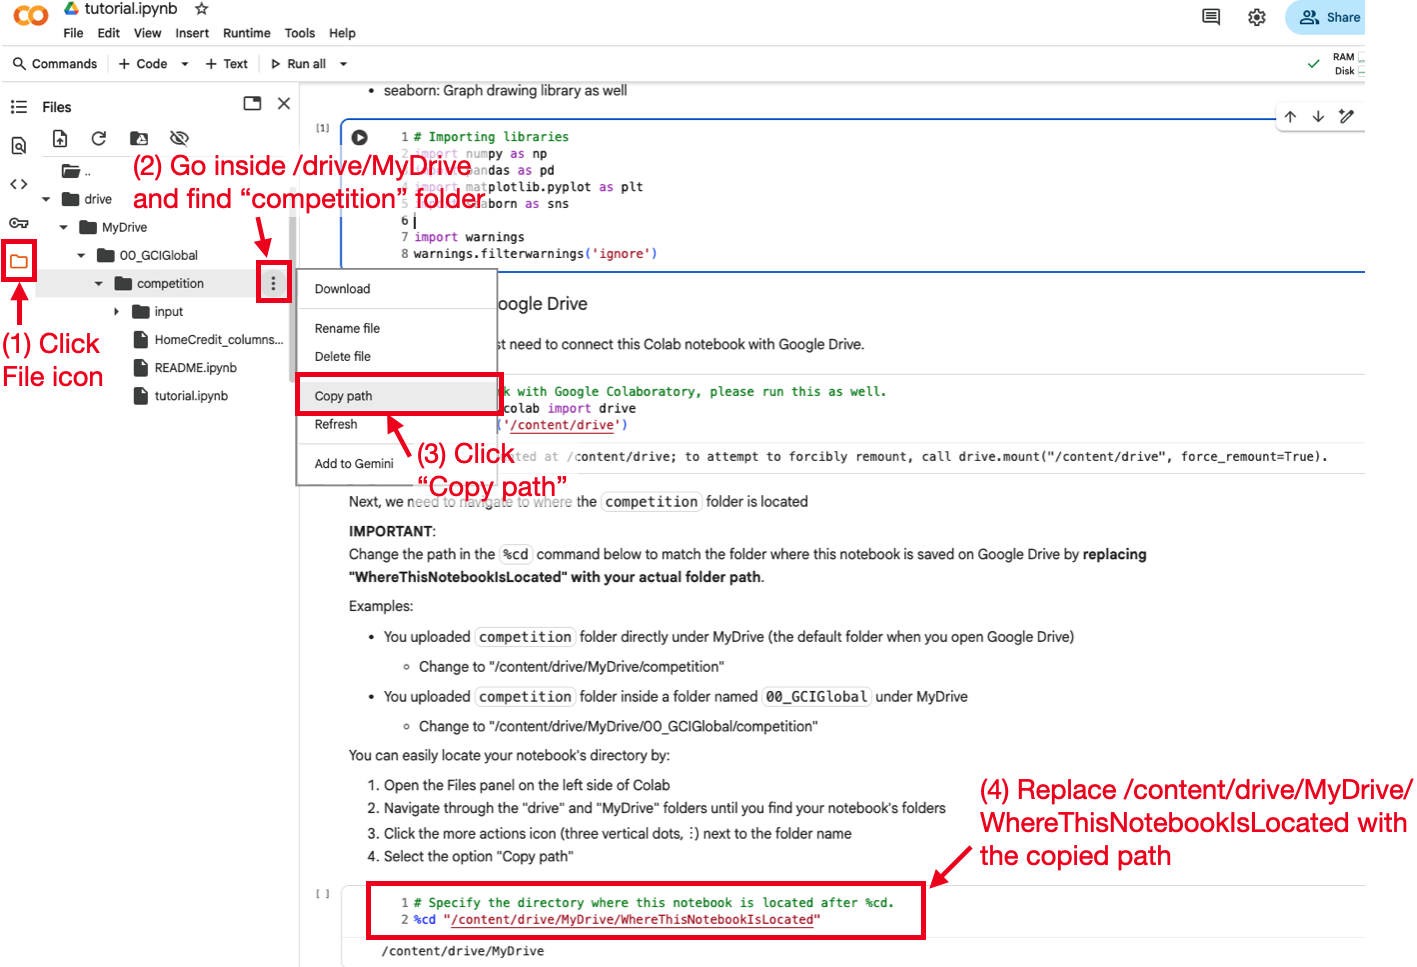

Run the cell below to check if the path is correctly set.

In [ ]:
from pathlib import Path

PATH = Path.cwd() / "input"

train_file = PATH / "train.csv"
test_file = PATH / "test.csv"
sample_sub_file = PATH / "submission2.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


### 2.2 Data Overview
Run the cell to load the dataset as `pd.DataFrame`.

**IMPORTANT:**<br>
**When you make modifications to preprocessing or model training, always make sure to run all cells from this cell.**

First, let's check the shape of the dataset.

In [ ]:
print('Train:', train.shape)
print('Test:', test.shape)

Train: (2781, 32)
Test: (696, 31)


We can see that the training data contains **2,781 rows** and **16 columns**, while the test data contains **696 rows** and **15 columns**.
The test data has one fewer column because it does not include the target variable to be predicted.

Next, let's take a look at the **first five rows** of the training data.

In [ ]:
train.head()

,Year,Age,Height,Weight,Sprint_40yd,Vertical_Jump,Bench_Press_Reps,Broad_Jump,Agility_3cone,Shuttle,...,Position_Type_defensive_lineman,Position_Type_kicking_specialist,Position_Type_line_backer,Position_Type_offensive_lineman,Position_Type_other_special,BMI,Jump_Power_Ratio,Sprint_Power_Ratio,Agility_Shuttle_Ratio,Agility_PCA
0,2011,21.0,1.9050,140.160042,5.39,59.69,29.0,251.46,7.910,4.940,...,False,False,False,True,False,38.621956,0.425870,0.038456,1.601215,0.887815
1,2011,24.0,1.8288,87.089735,4.31,101.60,16.0,332.74,6.948,4.214,...,False,False,False,False,False,26.039614,1.166613,0.049489,1.648790,-0.311642
2,2018,21.0,1.8542,92.986436,4.51,91.44,10.0,309.88,6.950,4.370,...,False,False,False,False,False,27.046212,0.983369,0.048502,1.590389,-0.228559
3,2010,21.0,1.9304,148.778297,5.09,76.20,39.0,254.00,8.120,4.710,...,True,False,False,False,False,39.925004,0.512171,0.034212,1.723992,0.947000
4,2016,21.0,1.8796,92.079251,4.64,78.74,14.8,281.94,7.130,4.200,...,False,False,False,False,False,26.063390,0.855133,0.050391,1.697619,-0.163670


You can view detailed information about a pandas DataFrame by using `.info()`.

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2781 entries, 0 to 2780
Data columns (total 32 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Year                              2781 non-null   int64  
 1   Age                               2781 non-null   float64
 2   Height                            2781 non-null   float64
 3   Weight                            2781 non-null   float64
 4   Sprint_40yd                       2781 non-null   float64
 5   Vertical_Jump                     2781 non-null   float64
 6   Bench_Press_Reps                  2781 non-null   float64
 7   Broad_Jump                        2781 non-null   float64
 8   Agility_3cone                     2781 non-null   float64
 9   Shuttle                           2781 non-null   float64
 10  Position                          2781 non-null   float64
 11  Drafted                           2781 non-null   float64
 12  Age_mi

In [ ]:
train.describe()

,Year,Age,Height,Weight,Sprint_40yd,Vertical_Jump,Bench_Press_Reps,Broad_Jump,Agility_3cone,Shuttle,...,Vertical_Jump_missing,Bench_Press_Reps_missing,Broad_Jump_missing,Agility_3cone_missing,Shuttle_missing,BMI,Jump_Power_Ratio,Sprint_Power_Ratio,Agility_Shuttle_Ratio,Agility_PCA
count,2781.000000,2781.000000,2781.000000,2781.000000,2781.000000,2781.000000,2781.000000,2781.000000,2781.000000,2781.000000,...,2781.000000,2781.000000,2781.000000,2781.000000,2781.000000,2781.000000,2781.000000,2781.000000,2781.000000,2.781000e+03
mean,2013.838907,21.994462,1.873590,109.502026,4.764843,83.313644,20.135563,291.524230,7.207323,4.387292,...,0.199209,0.259259,0.208918,0.348795,0.327940,31.020999,0.796696,0.044554,1.643577,1.453151e-16
std,3.083247,0.910236,0.067178,20.307239,0.295815,10.219461,5.979482,22.957832,0.383464,0.246627,...,0.399477,0.438307,0.406609,0.476675,0.469547,4.409766,0.206695,0.005937,0.042035,4.455577e-01
min,2009.000000,18.000000,1.651000,67.585263,4.220000,44.450000,2.000000,198.120000,6.280000,3.820000,...,0.000000,0.000000,0.000000,0.000000,0.000000,21.609798,0.316507,0.031158,1.459821,-1.024485e+00
25%,2011.000000,21.000000,1.828800,92.986436,4.530000,77.470000,16.000000,279.400000,6.940000,4.210000,...,0.000000,0.000000,0.000000,0.000000,0.000000,27.442010,0.636794,0.039121,1.618625,-3.144111e-01
50%,2014.000000,22.000000,1.879600,104.779837,4.690000,83.820000,20.000000,294.640000,7.100000,4.330000,...,0.000000,0.000000,0.000000,0.000000,0.000000,30.080665,0.812866,0.044646,1.643550,-1.304695e-01
75%,2017.000000,23.000000,1.930400,124.284309,4.950000,90.170000,24.000000,307.340000,7.402000,4.520000,...,0.000000,1.000000,0.000000,1.000000,1.000000,33.872330,0.957469,0.049163,1.669474,2.293208e-01
max,2019.000000,28.000000,2.082800,162.386068,6.000000,114.300000,45.000000,373.380000,9.040000,5.560000,...,1.000000,1.000000,1.000000,1.000000,1.000000,44.680097,1.416802,0.064659,1.830649,2.175308e+00


In [ ]:
test.describe()

,Year,Age,Height,Weight,Sprint_40yd,Vertical_Jump,Bench_Press_Reps,Broad_Jump,Agility_3cone,Shuttle,...,Bench_Press_Reps_missing,Broad_Jump_missing,Agility_3cone_missing,Shuttle_missing,Position_Type_other_special,BMI,Jump_Power_Ratio,Sprint_Power_Ratio,Agility_Shuttle_Ratio,Agility_PCA
count,696.000000,696.000000,696.000000,696.000000,696.000000,696.000000,696.000000,696.000000,696.000000,696.000000,...,696.000000,696.000000,696.000000,696.000000,696.0,696.000000,696.000000,696.000000,696.000000,696.000000
mean,2013.762931,21.958908,1.875476,110.722810,4.787167,82.593793,20.136782,289.408914,7.242836,4.411701,...,0.264368,0.211207,0.354885,0.327586,0.0,31.287859,0.783365,0.044321,1.642666,0.043031
std,3.046376,0.925595,0.068770,21.161295,0.307054,10.264938,6.363341,23.488828,0.388058,0.255732,...,0.441313,0.408458,0.478823,0.469671,0.0,4.547393,0.209220,0.005998,0.041694,0.454729
min,2009.000000,19.000000,1.676400,76.657111,4.280000,52.070000,6.000000,210.820000,6.500000,3.810000,...,0.000000,0.000000,0.000000,0.000000,0.0,23.734023,0.324279,0.031665,1.500219,-0.796959
25%,2011.000000,21.000000,1.828800,92.986436,4.540000,74.930000,15.350000,276.860000,6.970000,4.229000,...,0.000000,0.000000,0.000000,0.000000,0.0,27.615111,0.603546,0.038631,1.618692,-0.280170
50%,2014.000000,22.000000,1.879600,104.779837,4.710000,83.820000,20.000000,293.624000,7.130000,4.350000,...,0.000000,0.000000,0.000000,0.000000,0.0,30.212598,0.805993,0.044613,1.642382,-0.084716
75%,2016.000000,22.400000,1.930400,131.995380,5.010000,90.170000,24.400000,304.800000,7.452500,4.580000,...,1.000000,0.000000,1.000000,1.000000,0.0,34.925499,0.950415,0.049065,1.665568,0.311504
max,2019.000000,27.000000,2.032000,167.375585,5.760000,111.760000,49.000000,345.440000,8.720000,5.380000,...,1.000000,1.000000,1.000000,1.000000,0.0,44.461334,1.292248,0.062175,1.790640,1.688958


In [ ]:
train.duplicated().sum()

np.int64(0)

### [Next Steps]

This section only loaded the data. A few easy starting points to dig deeper before EDA:

- Run `train.describe()` and `test.describe()` to see summary statistics for the numerical columns.
- Check for duplicate rows with `train.duplicated().sum()`.
- Compare basic statistics (mean, std, min, max) between **train** and **test** to check whether the two splits look similar.

## 3.Data Analysis & EDA

**EDA (Exploratory Data Analysis)** is an essential step for understanding the structure and characteristics of your data before building a model.

At this stage, you explore trends and patterns in the dataset, as well as **outliers**, **missing values**, and **imbalanced distributions**. For example, some variables may contain extreme values, or the data may be heavily skewed toward specific categories. Identifying these characteristics helps you find potential issues that could hurt performance and uncover features that may be useful for prediction.

By performing EDA, you can detect and address problems early—such as “training fails due to missing values” or “the model becomes unstable because of outliers.” This reduces rework later and enables more efficient preprocessing and feature engineering.

Insights from EDA also inform later decisions, including model selection and hyperparameter tuning. In machine learning competitions, EDA is often a key process for improving final scores.

### 3.1 Checking Missing Values

First, let's check for missing values. This is an essential step in machine-learning-based data analysis, because most machine learning models cannot train on or make predictions from data that contains missing values, and will raise an error.

In [ ]:
train.isnull().sum()

,0
Year,0
Age,0
Height,0
Weight,0
Sprint_40yd,0
Vertical_Jump,0
Bench_Press_Reps,0
Broad_Jump,0
Agility_3cone,0
Shuttle,0


In [ ]:
test.isnull().sum()

,0
Year,0
Age,0
Height,0
Weight,0
Sprint_40yd,0
Vertical_Jump,0
Bench_Press_Reps,0
Broad_Jump,0
Agility_3cone,0
Shuttle,0


We found missing values in the following columns: **Age**,**Sprint_40yd**, **Vertical_Jump**, **Bench_Press_Reps**, **Broad_Jump**, **Agility_3cone**, and **Shuttle**. We will handle these later.

### 3.2 Visualization and Analysis

Next, let's look at how many players were drafted.

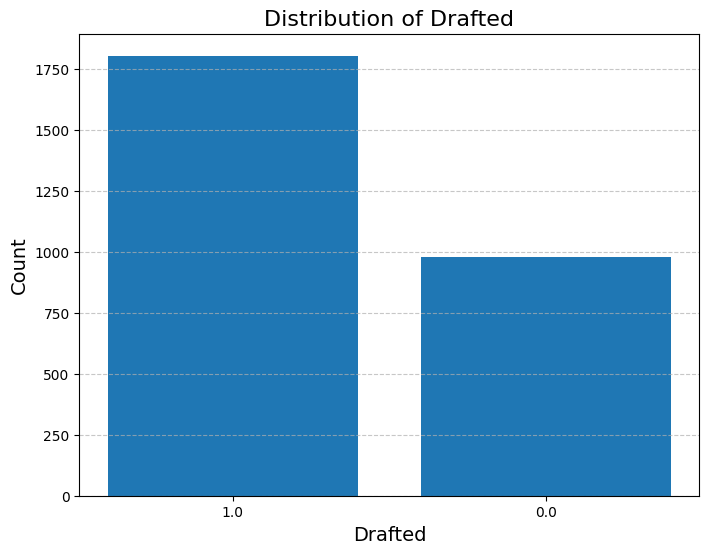

In [ ]:
drafted_counts = train['Drafted'].value_counts()

plt.figure(figsize=(8, 6))
plt.bar(drafted_counts.index.astype(str), drafted_counts.values)
plt.title('Distribution of Drafted', fontsize=16)
plt.xlabel('Drafted', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

We can see that there are more players with **Drafted = 1** than those with **Drafted = 0**. Let's check the propotions.

In [ ]:
drafted_percentage = train['Drafted'].value_counts(normalize=True) * 100

print(f"Percentage of 0: {drafted_percentage.get(0, 0):.2f}%")
print(f"Percentage of 1: {drafted_percentage.get(1, 0):.2f}%")

Percentage of 0: 35.17%
Percentage of 1: 64.83%


We found that about **35%** of the players were **not drafted**, while about **65%** were **drafted**.

Next, we will continue EDA for the other features. First, let's visualize the numerical variables excluding the **"Id"** and **"Drafted"** columns.

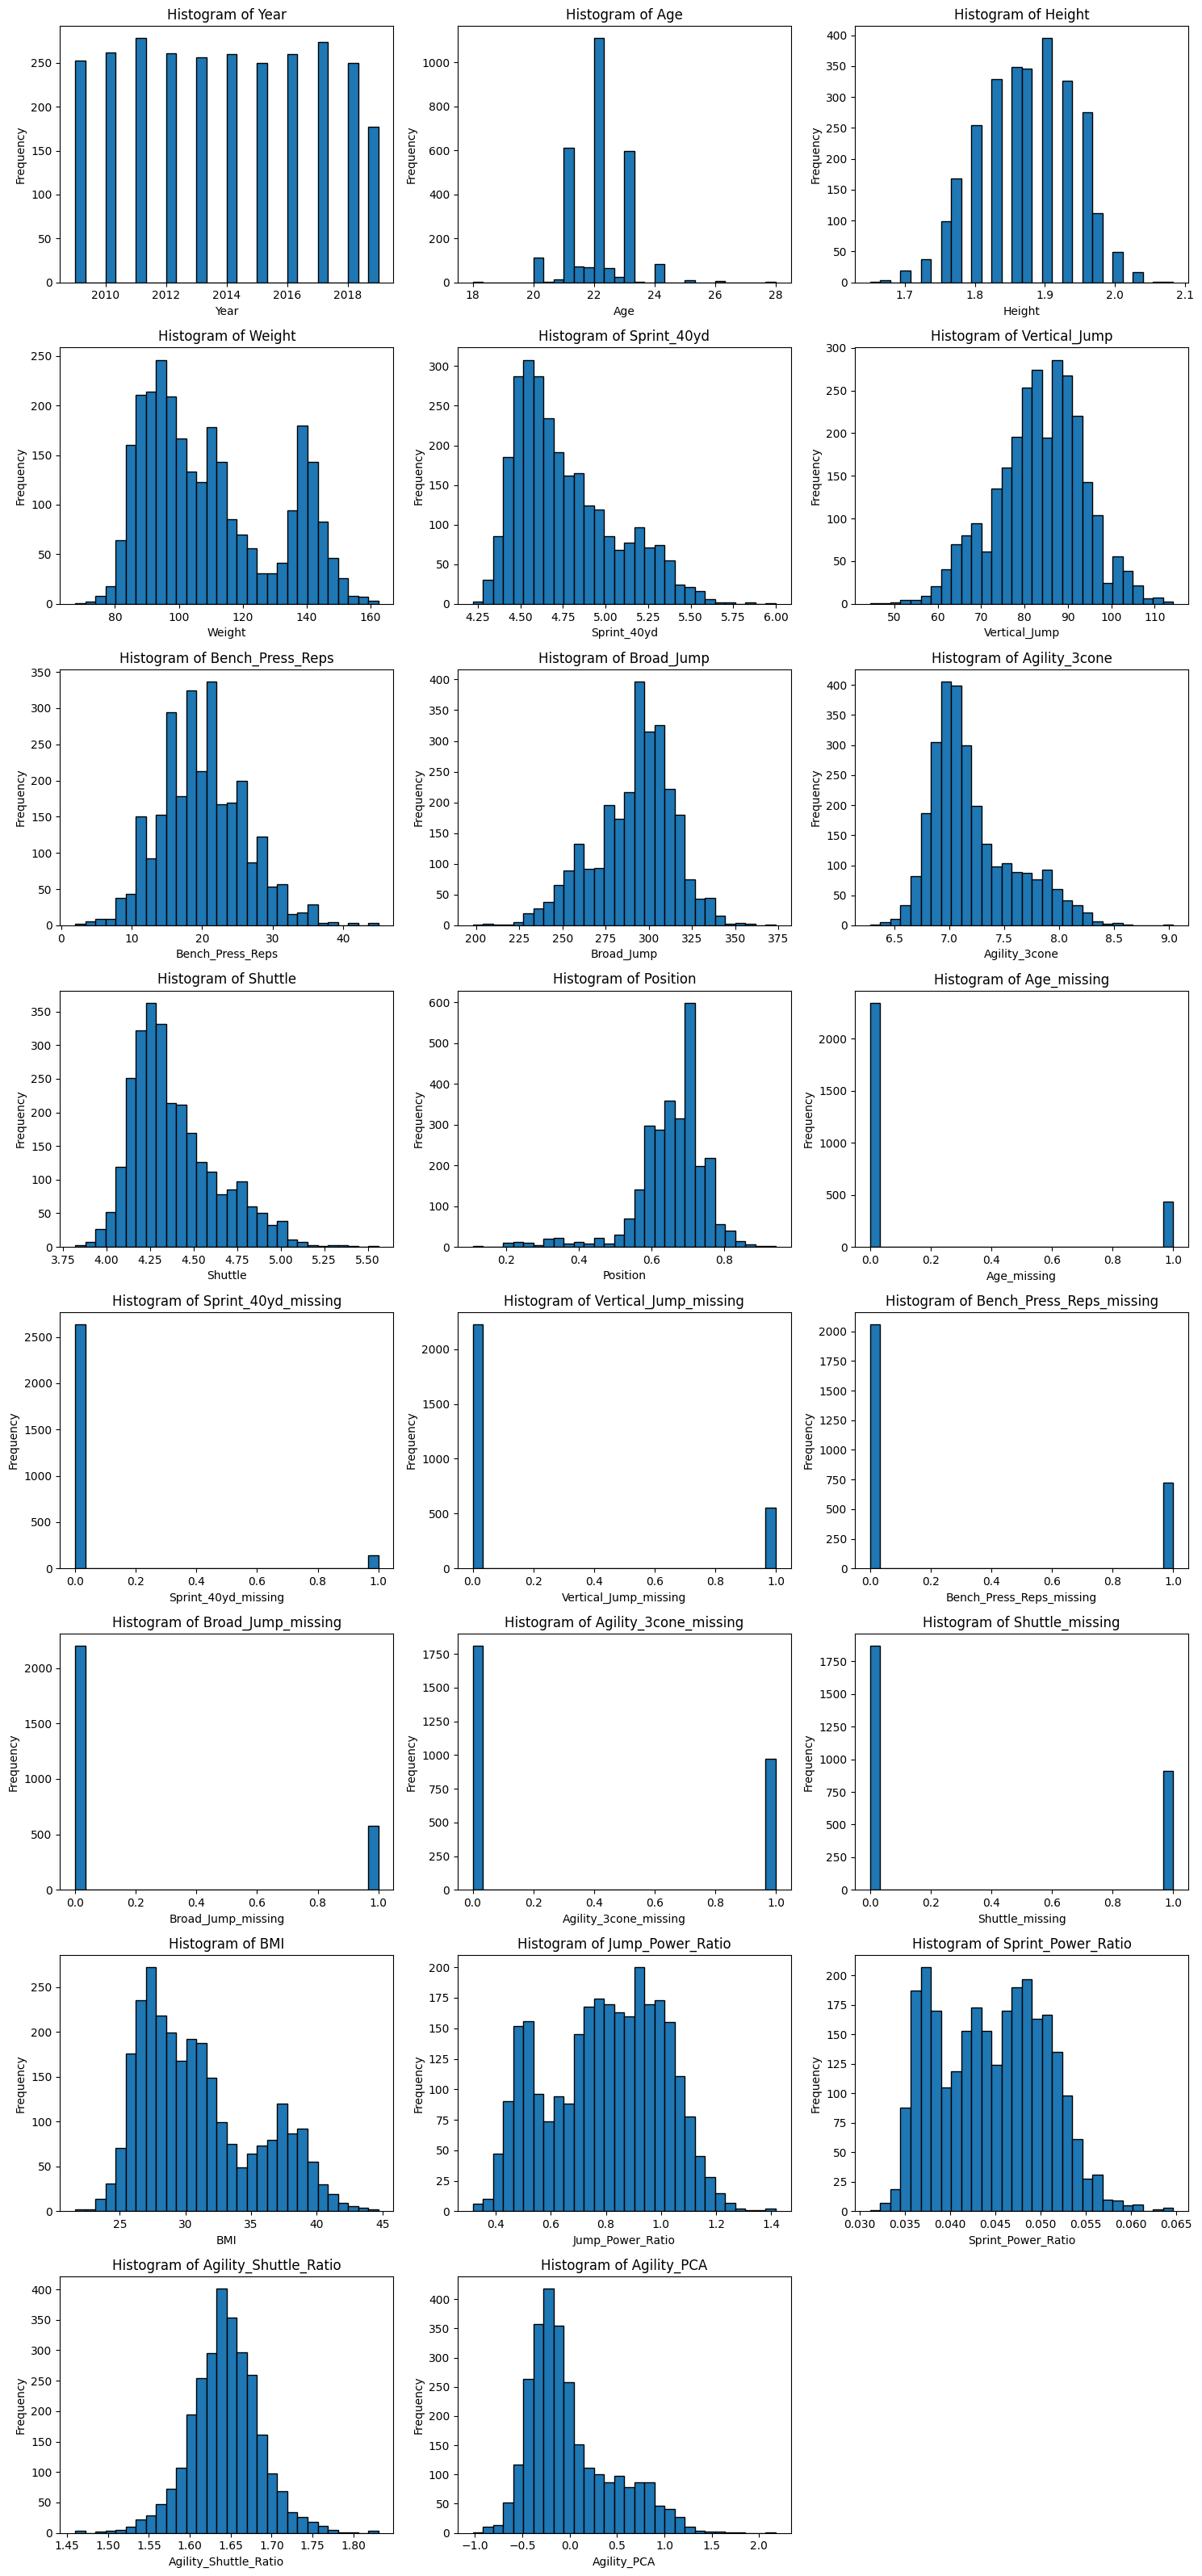

In [ ]:
from sklearn.decomposition import PCA
# Extraxt numeric columns (excluding the 'Id' and 'Drafted' columns)
numeric_cols = train.select_dtypes(include=['number']).columns
numeric_cols = numeric_cols.drop('Drafted') # 'Id' was already dropped from train dataframe

# Plot
num_cols = len(numeric_cols)
cols = 3
rows = (num_cols + cols - 1) // cols

plt.figure(figsize=(5 * cols, 4 * rows))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(rows, cols, i)
    plt.hist(train[col].dropna(), bins=30, edgecolor='black')
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

Let's examine the correlation matrix of the numerical features using a heatmap.

In [ ]:
# Extract numeric columns (excluding the 'Id' and ''Drafted' columns)
numeric_cols = train.select_dtypes(include=['number']).drop(['Id', 'Drafted'], axis=1)

# Compute the correlation matrix
corr_matrix = numeric_cols.corr()

# Plot a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5
)

plt.title('Correlation Matrix of Numeric Features', fontsize=16)
plt.show()

KeyError: "['Id'] not found in axis"

The correlation coefficient between **Agility_3cone** and **Shuttle** is **0.88**, indicating a strong positive relationship. These tests may rely on similar muscle groups and movement patterns.

On the other hand, the correlation coefficient between **Sprint_40yd** and **Broad_Jump** is **-0.82**, showing a strong negative relationship. Since both events mainly depend on lower-body power, we might normally expect their scores to move together (i.e., a positive correlation), but here we observe the opposite. To investigate this further, let’s visualize **Sprint_40yd**.

In [ ]:
# Plot a boxplot
plt.figure(figsize=(6, 3))
sns.boxplot(x=train['Sprint_40yd'])

plt.title('Box Plot of Sprint_40yd', fontsize=16)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

From the plot, we can see that values in **Sprint_40yd** are roughly distributed between **4.25** and **6.00**. This suggests the column likely represents the **actual sprint time**, not a “score.” A median of around **4.7 seconds** is reasonable for a 40-yard (about 36-meter) dash.

In other words, **smaller values** in **Sprint_40yd** mean faster times, so **lower is better**—the opposite direction from metrics where **higher values indicate better performance**. This explains why we observed a negative correlation with **Broad_Jump**.

By visualizing the data, we were able to answer the question: **“Why is there a negative correlation?”**

Next, let's visualize the categorical features.

In [ ]:
# Extract categorical features
categorical_cols = train.select_dtypes(include=['object', 'category']).columns

# Get the number of unique categories in each column
levels_count = {col: train[col].nunique() for col in categorical_cols}

for col, count in levels_count.items():
    print(f"{col}: {count} levels")


**'School'** has **236** unique values, which is too many to visualize clearly, so we will exclude it from the plots here.

In [ ]:
# Extract categorical features (object or category) and exclude the 'School' columns
categorical_cols = train.select_dtypes(include=['object', 'category']).columns
categorical_cols = categorical_cols.drop('School')

# Prepare for plotting
num_cols = len(categorical_cols)
rows = 1
cols = num_cols

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5))

if cols == 1:
    axes = [axes]
else:
    axes = axes.flatten()

# Count plots for each categorical features
for i, col in enumerate(categorical_cols):
    sns.countplot(x=col, data=train, order=train[col].value_counts().index, ax=axes[i])
    axes[i].set_title(f'Count Plot of {col}', fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Count', fontsize=12)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

We can see that the number of samples varies widely across categories. For example, in the **Player_Type** column, the **special_teams** category has very few samples.

Next, let's visualize the **mean value of "Drafted"** for each category level. This helps us understand, visually, which positions are more likely to be drafted.

In [ ]:
# Extract categorical features (object or category) and exclude the 'School' column
categorical_cols = train.select_dtypes(include=['object', 'category']).columns
categorical_cols = categorical_cols.drop('School')

# Prepare for plotting
num_cols = len(categorical_cols)
rows = 1
cols = num_cols

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5))

if cols == 1:
    axes = [axes]
else:
    axes = axes.flatten()

# Plot the mean value of 'Drafted' for each categorical feature as bar charts
for i, col in enumerate(categorical_cols):
    mean_values = train.groupby(col)['Drafted'].mean().sort_values(ascending=False)
    sns.barplot(x=mean_values.index, y=mean_values.values, ax=axes[i])
    axes[i].set_title(f'Average Drafted by {col}', fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Average Drafted', fontsize=12)
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


We can see that players with **Player_Type = "special_teams"** have a much lower draft rate than other players.
Similarly, players with **Position_Type = "other_special"** or **"kicking_specialist"**, and those with **Position = "LS"**, **"K"**, or **"P"**, also have relatively low draft rates.

### [Next Steps]

EDA is open-ended; here are some directions you can take next:

- Examine the relationship between each numerical feature and the target with grouped boxplots (`sns.boxplot(x='Drafted', y=col, ...)`).
- Cross-tabulate categorical features against **Drafted** to see which categories have a high or low draft rate.
- Investigate the **School** column more carefully — for example, group schools by conference or region and check the draft rate per group.
- Look for outliers in other numerical columns (e.g. **Bench_Press_Reps**, **Vertical_Jump**) and decide how to handle them.

## 4.Preprocessing

Here, we will conduct the preprocessing and create new features based on what we have learned in the preceding visualization and analysis. We will perform **missing value imputation** and **encoding**.

### 4.1 Dropping Columns

In this notebook, we will exclude categorical features with a relatively large number of unique levels. Specifically, we will drop the **School** column (**236** unique values). *(Note: School may still influence Drafted; if you want to explore further, try including it as a feature.)* We will also drop the **Id** column, since it is expected to be unrelated to whether a player is drafted.

In [ ]:
# Drop unused columns
train = train.drop(columns=["Id", "School"])
test = test.drop(columns=["Id","School"])

### 4.2 Dealing Missing Values

There are missing values in **Age**, **Sprint_40yd**, **Vertical_Jump**, **Bench_Press_Reps**, **Broad_Jump**, **Agility_3cone**, and **Shuttle**. In this notebook, we will impute these missing values using the mean of each column.

Missingness itself can be informative (e.g., players who skipped certain tests might be less likely drafted). Adding binary indicators allows the model to learn that pattern.

In [ ]:
# Columns to impute with the mean

cols_to_fill = ['Age', 'Sprint_40yd', 'Vertical_Jump', 'Bench_Press_Reps',
                'Broad_Jump', 'Agility_3cone', 'Shuttle']
'''
# Impute both train and test using the means computed from the training data
for col in cols_to_fill:
    mean_value = train[col].mean()
    train[col] = train[col].fillna(mean_value)
    test[col] = test[col].fillna(mean_value)
'''
#missing value indicator
for col in cols_to_fill:
    train[f'{col}_missing'] = train[col].isna().astype(int)
    test[f'{col}_missing'] = test[col].isna().astype(int)

## Median Imputation (robust to outliers)

In [ ]:
# Impute missing values with median (from training)
'''
cols_to_fill = ['Age', 'Sprint_40yd', 'Vertical_Jump', 'Bench_Press_Reps',
                'Broad_Jump', 'Agility_3cone', 'Shuttle']

for col in cols_to_fill:
    median_value = train[col].median()
    train[col] = train[col].fillna(median_value)
    test[col] = test[col].fillna(median_value)
'''
from sklearn.impute import KNNImputer
# Select numeric columns for KNN imputation
num_cols = ['Age', 'Height', 'Weight', 'Sprint_40yd', 'Vertical_Jump',
            'Bench_Press_Reps', 'Broad_Jump', 'Agility_3cone', 'Shuttle']

# Fit imputer on training data only
imputer = KNNImputer(n_neighbors=5)
train[num_cols] = imputer.fit_transform(train[num_cols])
test[num_cols] = imputer.transform(test[num_cols])

Let's check whether there are any missing values.

In [ ]:
train.isnull().sum()

,0
Year,0
Age,0
Height,0
Weight,0
Sprint_40yd,0
Vertical_Jump,0
Bench_Press_Reps,0
Broad_Jump,0
Agility_3cone,0
Shuttle,0


In [ ]:
test.isnull().sum()

,0
Year,0
Age,0
Height,0
Weight,0
Sprint_40yd,0
Vertical_Jump,0
Bench_Press_Reps,0
Broad_Jump,0
Agility_3cone,0
Shuttle,0


Now, the missing values in both **train** and **test** have been handled.

### 4.3 Dealing Categorical Data

Next, let's convert the categorical features into numerical values so they can be used as model imputs. Most machine learning models can only accept numerical data.

Here, we will use a technique called **label encoding**.

In [ ]:
'''
# Label-encode the categorical features
label_encoders = {}
for c in ["Player_Type", "Position_Type", "Position"]:
    label_encoders[c] = LabelEncoder()
    train[c] = label_encoders[c].fit_transform(train[c].astype(str))
    test[c] = label_encoders[c].transform(test[c].astype(str))
'''

'\n# Label-encode the categorical features\nlabel_encoders = {}\nfor c in ["Player_Type", "Position_Type", "Position"]:\n    label_encoders[c] = LabelEncoder()\n    train[c] = label_encoders[c].fit_transform(train[c].astype(str))\n    test[c] = label_encoders[c].transform(test[c].astype(str))\n'

One Hot Encoding

In [ ]:
'''
# One-hot encode categorical features (excluding 'Position' if too many levels)
cat_cols = ['Player_Type', 'Position_Type']

# Apply one-hot
train = pd.get_dummies(train, columns=cat_cols, drop_first=True)
test = pd.get_dummies(test, columns=cat_cols, drop_first=True)
# Align test columns to train (in case of missing categories)
test = test.reindex(columns=train.columns, fill_value=0)
'''

"\n# One-hot encode categorical features (excluding 'Position' if too many levels)\ncat_cols = ['Player_Type', 'Position_Type']\n\n# Apply one-hot\ntrain = pd.get_dummies(train, columns=cat_cols, drop_first=True)\ntest = pd.get_dummies(test, columns=cat_cols, drop_first=True)\n# Align test columns to train (in case of missing categories)\ntest = test.reindex(columns=train.columns, fill_value=0)\n"

 Encode Categorical Features (Target Encoding for Position

In [ ]:
import category_encoders as ce
# 6a. One-hot encode low-cardinality columns
#     (Player_Type: 3 levels, Position_Type: 7 levels)
# These columns were already one-hot encoded in a previous step, so skip this.

# Define X_sel (features) and y (target) from the current train DataFrame *before* target encoding
X_features = train.drop(columns=['Drafted'])
y = train['Drafted']

# 6b. Target encode 'Position' using CatBoostEncoder
# Note: 'Position' column is already float64. CatBoostEncoder can still be applied, but ensure this is the intended behavior.
encoder = ce.CatBoostEncoder(cols=['Position'])

# Fit the encoder on the training features (X_features) and the target (y)
# Then transform the training features, storing the result in X_sel
X_sel = encoder.fit_transform(X_features, y)

# Transform the test set features using the fitted encoder
test = encoder.transform(test)

# Align test to X_sel columns (just in case)
test = test.reindex(columns=X_sel.columns, fill_value=0)

ValueError: Unexpected input dimension 31, expected 32

## 5.Model

Now that the data has been prepared, we will use it as input to build a model

random forest

In [ ]:
X = train.drop(columns=['Drafted'])
y = train['Drafted']

# Final alignment
test = test.reindex(columns=X.columns, fill_value=0)

print(f"X shape: {X.shape}, test shape: {test.shape}")

In [ ]:
'''
# Split into features and target
X = train.drop(columns=["Drafted"])
y = train["Drafted"]

# Set up the model and cross-validation
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=2025
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Store scores
auc_scores = []

# Train and evaluate using Startified K-Fold cross-validation
for fold, (train_idx, valid_idx) in enumerate(skf.split(X, y)):
    print(f"Fold {fold + 1}")

    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    # Train the model
    model.fit(X_train, y_train)

    # Predict and score
    y_valid_pred_proba = model.predict_proba(X_valid)[:, 1]
    auc = roc_auc_score(y_valid, y_valid_pred_proba)
    auc_scores.append(auc)
    print(f"  AUC: {round(auc, 4)}")

# Print mean AUC
mean_auc = np.mean(auc_scores)
print("\nAverage Validation AUC:", round(mean_auc, 4))
'''

## 6. Hypotheses & Feature Engineering

Here, we will perform **feature engineering**.

Feature engineering is the process of creating new features from the original data so that the model can learn more effectively. It is one of the key steps for improving model performance.

Here, based on the hypothesis that **BMI**, a measure of body composition caluculated from height and weight, may be informative for predicting draft outcomes, we will create a new feature by computing.

**BMI = weight / (height)²**

In [ ]:
from sklearn.decomposition import PCA
# 5.1 BMI
for df in [train, test]:
    df['BMI'] = df['Weight'] / (df['Height'] ** 2)

# 5.2 Ratio features
for df in [train, test]:
    df['Jump_Power_Ratio'] = df['Vertical_Jump'] / df['Weight']
    df['Sprint_Power_Ratio'] = df['Sprint_40yd'] / df['Weight']
    df['Agility_Shuttle_Ratio'] = df['Agility_3cone'] / df['Shuttle']

# 5.3 PCA on agility tests
agility_cols = ['Agility_3cone', 'Shuttle']
pca = PCA(n_components=1)
train['Agility_PCA'] = pca.fit_transform(train[agility_cols])
test['Agility_PCA'] = pca.transform(test[agility_cols])

Let's re-evaluate the model, this time including the newly created feature.

In [ ]:
from sklearn.feature_selection import RFE

selector = RFE(RandomForestClassifier(n_estimators=100, max_depth=5, random_state=2025), n_features_to_select=15)
selector.fit(X, y)
selected_features = X.columns[selector.support_]
print("Selected features:", selected_features)

# Then use only these features in training
X_sel = X[selected_features]
test_sel = test[selected_features]
# After all preprocessing, align test columns to train
test = test.reindex(columns=train.columns.drop("Drafted"), fill_value=0)


In [ ]:

# Split into features and target
X_sel = train.drop(columns=["Drafted"])
y = train["Drafted"]
test = test.reindex(columns=train.columns.drop("Drafted"), fill_value=0)
# Set up the model and cross-validation
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=2,
    random_state=2025
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Store scores
auc_scores = []

# Train and evaluate using Stratified K-fold cross-validation
for fold, (train_idx, valid_idx) in enumerate(skf.split(X_sel, y)):
    print(f"Fold {fold + 1}")

    X_train, X_valid = X_sel.iloc[train_idx], X_sel.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    model.fit(X_train, y_train)

    y_valid_pred_proba = model.predict_proba(X_valid)[:, 1]
    auc = roc_auc_score(y_valid, y_valid_pred_proba)
    auc_scores.append(auc)
    print(f"  AUC: {round(auc, 4)}")

mean_auc = np.mean(auc_scores)
print("\nAverage Validation AUC:", round(mean_auc, 4))


In [ ]:
'''
# Base models
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=2025,
    eval_metric='auc'
)

lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=2025,
    verbose=-1
)

cb_model = cb.CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    random_seed=2025,
    verbose=False
)

# Meta‑learner
meta_model = LogisticRegression(max_iter=1000, random_state=2025)
'''

In [ ]:
'''
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Redefine X to include the new features added in cell cfXMqJ1ygSCK
X = train.drop(columns=['Drafted'])
y = train['Drafted']

# Ensure test columns match X exactly
test = test.reindex(columns=X.columns, fill_value=0)

# Arrays to store out‑of‑fold predictions for meta‑training
oof_xgb = np.zeros((X.shape[0], 1))
oof_lgb = np.zeros((X.shape[0], 1))
oof_cb = np.zeros((X.shape[0], 1))

# Arrays to store test predictions from each fold
test_xgb = np.zeros((test.shape[0], 1))
test_lgb = np.zeros((test.shape[0], 1))
test_cb = np.zeros((test.shape[0], 1))

print(f"Generating out-of-fold predictions with {X.shape[1]} features...\n")

for fold, (train_idx, valid_idx) in enumerate(skf.split(X, y)):
    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    # XGBoost
    xgb_model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
    oof_xgb[valid_idx] = xgb_model.predict_proba(X_valid)[:, 1].reshape(-1, 1)
    test_xgb += xgb_model.predict_proba(test)[:, 1].reshape(-1, 1) / skf.get_n_splits()

    # LightGBM
    lgb_model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)])
    oof_lgb[valid_idx] = lgb_model.predict_proba(X_valid)[:, 1].reshape(-1, 1)
    test_lgb += lgb_model.predict_proba(test)[:, 1].reshape(-1, 1) / skf.get_n_splits()

    # CatBoost
    cb_model.fit(X_train, y_train, eval_set=(X_valid, y_valid), verbose=False)
    oof_cb[valid_idx] = cb_model.predict_proba(X_valid)[:, 1].reshape(-1, 1)
    test_cb += cb_model.predict_proba(test)[:, 1].reshape(-1, 1) / skf.get_n_splits()

    print(f"Fold {fold+1} complete")

# Combine out-of-fold predictions for meta-training
meta_X = np.hstack([oof_xgb, oof_lgb, oof_cb])
meta_y = y.values

# Train meta-learner
meta_model.fit(meta_X, meta_y)

# Combine test predictions
test_meta = np.hstack([test_xgb, test_lgb, test_cb])
test_pred_proba = meta_model.predict_proba(test_meta)[:, 1]
'''

In [ ]:
'''
# We can evaluate the ensemble using the same CV folds
ens_preds = np.zeros((X.shape[0], 1))

for fold, (train_idx, valid_idx) in enumerate(skf.split(X, y)):
    # (Reuse earlier folds – but we already have oof predictions)
    meta_train = meta_X[train_idx]
    meta_valid = meta_X[valid_idx]
    meta_model.fit(meta_train, y.iloc[train_idx])
    ens_preds[valid_idx] = meta_model.predict_proba(meta_valid)[:, 1].reshape(-1, 1)

auc = roc_auc_score(y, ens_preds)
print(f"Ensemble validation AUC (CV): {auc:.4f}")
'''

In [ ]:
import xgboost as xgb
# Set up cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Store scores
auc_scores = []
model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    early_stopping_rounds=20,
    random_state=2025,
    eval_metric='auc'
)
if 'Drafted' in test.columns:
    test = test.drop(columns=['Drafted'])

test = test.reindex(columns=X_sel.columns, fill_value=0)
# Train and evaluate
for fold, (train_idx, valid_idx) in enumerate(skf.split(X_sel, y)):
    print(f"Fold {fold + 1}")

    X_train, X_valid = X_sel.iloc[train_idx], X_sel.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    model.fit(
        X_train, y_train,
        eval_set=[(X_valid, y_valid)],
        verbose=False
    )

    y_valid_pred_proba = model.predict_proba(X_valid)[:, 1]
    auc = roc_auc_score(y_valid, y_valid_pred_proba)
    auc_scores.append(auc)
    print(f"  AUC: {round(auc, 4)}")

mean_auc = np.mean(auc_scores)
print(f"\nAverage Validation AUC: {round(mean_auc, 4)}")

Some machine learning models can compute the importance of the input features. Let's visualize the feature importances.

In [ ]:
# ──────────────────────────────────────────────────────────────
# Feature importances for XGBoost
# ──────────────────────────────────────────────────────────────
feature_importances = pd.DataFrame({
    'Feature': X_sel.columns,  # ← Use X_sel, not X
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Visualize
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importances, x='Importance', y='Feature')
plt.title('Feature Importances from XGBoost', fontsize=16)
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

The newly created feature, **BMI**, showed relatively high feature importance.

## 7.Create the Submission File

Finally, let's make a prediction for the test data, and prepare a CSV file to submit.

### 7.1 Predicting on the test data
We found in Sections 5 and 6 that the best model was Random Forest model with BMI column added. Therefore, we will use this model to make the final prediction.

If you made any changes and found a better model, you will need to change the code below accordingly.

In [ ]:
# ──────────────────────────────────────────────────────────────
# Align test columns to X_sel exactly
# ──────────────────────────────────────────────────────────────
# Drop 'Drafted' if present (it should not be in test)
if 'Drafted' in test.columns:
    test = test.drop(columns=['Drafted'])

# Reindex test to have same columns as X_sel, filling missing with 0
test = test.reindex(columns=X_sel.columns, fill_value=0)

# ──────────────────────────────────────────────────────────────
# Prediction loop
# ──────────────────────────────────────────────────────────────
test_pred_proba_list = []

for fold, (train_idx, valid_idx) in enumerate(skf.split(X_sel, y)):
    X_train, X_valid = X_sel.iloc[train_idx], X_sel.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    model.fit(
        X_train, y_train,
        eval_set=[(X_valid, y_valid)],
        verbose=False
    )

    test_pred_proba = model.predict_proba(test)[:, 1]
    test_pred_proba_list.append(test_pred_proba)

test_pred_proba_mean = np.mean(test_pred_proba_list, axis=0)
print(f"Test predictions averaged over folds as big as")

### 7.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [ ]:
# Running this cell will generate the submission CSV file
submission = pd.read_csv(PATH / 'sample_submission.csv') # Update PATH in needed
submission["Drafted"] = test_pred_proba_mean
submission.to_csv(PATH / 'submission1.csv', index=False)

At this point, you have successfully created a prediction CSV file that is ready for submission. Try submitting **submission.csv**.